# Instagram Reel Reach Prediction Before Posting
## Supervised Machine Learning Pipeline, Rigor Diagnostics, & Viva Defense Guide
**Author:** ML Engineering & Data Science Mentorship  
**Problem Type:** Supervised Regression  
**Target Variable:** `actual_reach` (Total unique accounts reached by the planned Reel)  
**Primary Baseline:** Ordinary Least Squares Linear Regression (Interpretable)  
**Comparison Models:** Ridge Regression, Random Forest Regressor, Gradient Boosting Regressor

---

### Non-Negotiable Methodological Principles & Viva Defense Framing

> **1. Zero Data Leakage Guarantee:**  
> This system uses **strictly pre-posting features** (historical account metrics and planned Reel metadata known prior to publication).  
> **Under no circumstances** do we include post-posting signals such as likes, comments, shares, saves, watch-time, or retention of the target Reel. Using post-launch engagement to predict reach is a severe methodological flaw (target leakage), as those metrics are outcomes of reach, not causes.

> **2. Statistical Framing vs Recommendation Algorithm:**  
> This model is a **statistical regression engine** estimating expected reach based on historical associations. It **does NOT replicate Meta's proprietary recommendation algorithm**, graph neural networks, or ranking infrastructure. The language used throughout is strictly *"associated with"*, never *"causes"*.

> **3. Honest Data Disclosure:**  
> In the absence of a public production dataset from Meta, this demonstration employs a calibrated **synthetic dataset** generated with documented domain uplifts and realistic mess (missing values, impossible entries, duplicate rows, extreme leverage points). Results validate **methodological rigor**, not literal Instagram production parameters.

> **4. Rigorous Regression Terminology:**  
> In supervised regression, the term *"accuracy"* is mathematically invalid (accuracy is a discrete classification metric). We measure model error using:
> - **MAE (Mean Absolute Error):** Average magnitude of prediction error in units of people reached.
> - **RMSE (Root Mean Squared Error):** Penalizes large viral estimation errors more heavily due to quadratic squaring.
> - **$R^2$ (Coefficient of Determination):** The share of variation in observed reach explained by the model on the test set.


In [1]:
# Core scientific and statistical libraries
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import joblib

# Add src to system path for modular imports
sys.path.append(os.path.abspath("../src"))
from preprocessing import (
    load_reels_data,
    clean_raw_reels_data,
    build_preprocessor_pipeline,
    TARGET_COLUMN
)
from train import (
    evaluate_regression,
    extract_pipeline_feature_names,
    compute_vif_dataframe
)

# Aesthetics and reproducibility settings
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["figure.dpi"] = 120
sns.set_palette("crest")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("[+] Setup complete. Random state locked at 42.")


[+] Setup complete. Random state locked at 42.


---
# PART 1: STAGE 1 (Core Linear Regression Pipeline)

## 1. Data Ingestion & Transparent Cleaning Report

Real-world social media exports contain telemetry glitches, human input typos, and transmission duplicates.  
Before any model touches the data, we perform systematic validation:
1. **Deduplication:** Remove exact duplicate rows resulting from accidental double-logging.
2. **Physical Bounds Validation:** Filter out impossible values:
   - `posting_hour` must be between $0$ and $23$.
   - `reel_duration` must be positive and $\le 300$ seconds (hard platform limits).
   - `hashtag_count` cannot be negative.
3. **Justified Outlier Handling (Winsorization):** Capping extreme tail anomalies (e.g., 50x reach glitch) at the 99.5th percentile.
   - *Viva Rationale:* Ordinary Least Squares (OLS) minimizes the sum of squared residuals ($\sum (y_i - \hat{y}_i)^2$). An extreme leverage point exerts quadratic distortion on regression slopes. Capping at 99.5% retains the observation while dampening destructive leverage.
4. **Zero-Leakage Imputation Policy:** Missing values ($NaN$) are retained at this stage and imputed strictly within the cross-validation / training pipeline using the training median (for numeric) and mode (for categorical).


In [2]:
# Load raw dataset
data_path = os.path.join("..", "data", "reels_dataset.csv")
raw_df = load_reels_data(data_path)
print(f"Loaded raw dataset with shape: {raw_df.shape}")

# Clean dataset and produce transparent audit report
clean_df, report = clean_raw_reels_data(raw_df, verbose=True)


Loaded raw dataset with shape: (4015, 15)
DATA CLEANING REPORT
Initial row count: 4015
Final row count:   3987 (Retained 99.3%)
Actions taken:
  • Removed 13 exact duplicate rows.
  • Dropped 6 rows with impossible posting_hour (<0 or >23).
  • Dropped 9 rows with impossible reel_duration (<=0s or >300s).
  • Fixed 6 rows with negative hashtag_count by setting to 0.
  • Winsorized 20 extreme reach outliers at 99.5th percentile (159138). Justification: Prevents severe leverage in squared-error linear regression.


---
## 2. Exploratory Data Analysis (EDA)

Here we inspect the statistical properties of the dataset to guide feature engineering and model selection.
Every plot is accompanied by a concise **"What this tells us"** takeaway for oral defense.


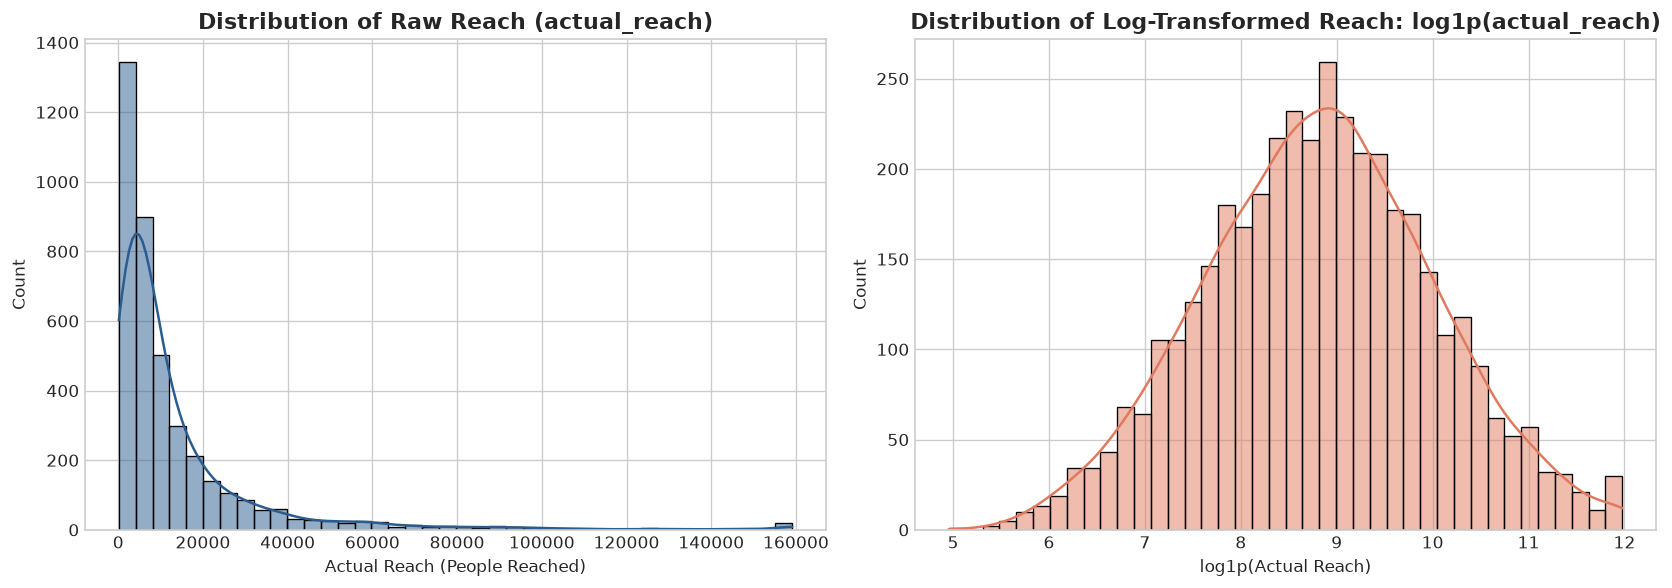

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Raw distribution
sns.histplot(clean_df[TARGET_COLUMN], kde=True, ax=axes[0], color="#2b5c8f", bins=40)
axes[0].set_title("Distribution of Raw Reach (actual_reach)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Actual Reach (People Reached)")
axes[0].set_ylabel("Count")

# Log1p distribution
sns.histplot(np.log1p(clean_df[TARGET_COLUMN]), kde=True, ax=axes[1], color="#e07a5f", bins=40)
axes[1].set_title("Distribution of Log-Transformed Reach: log1p(actual_reach)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("log1p(Actual Reach)")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()


> **What this tells us:**  
> The raw reach distribution exhibits extreme right-skewness, typical of viral social media reach where a minority of posts achieve massive reach. While Ordinary Least Squares linear regression can be fit directly on raw reach for intuitive coefficient interpretability, the heavy skew warns us that error variance will likely expand at higher reach levels (heteroscedasticity).


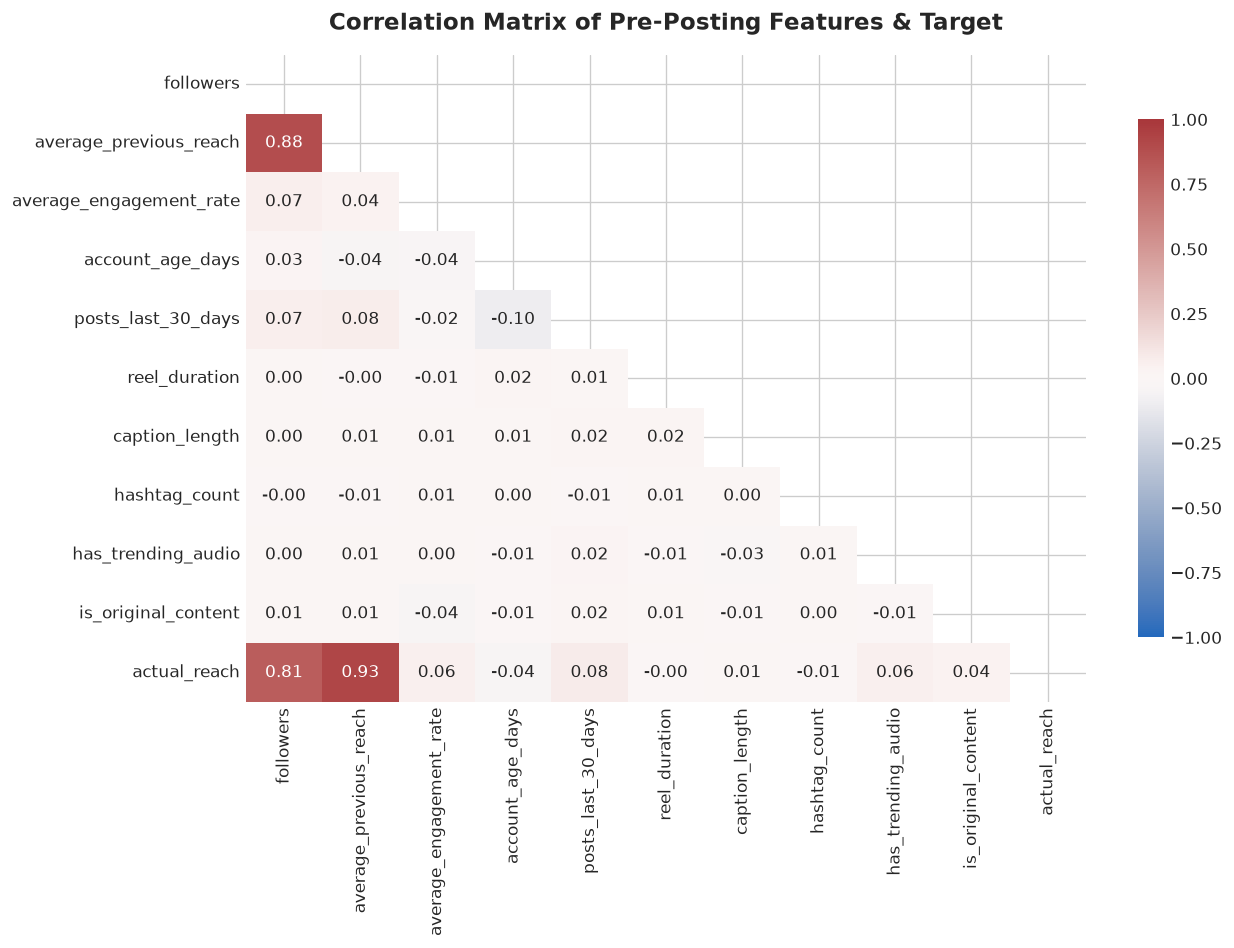

In [4]:
numeric_cols = [
    "followers", "average_previous_reach", "average_engagement_rate",
    "account_age_days", "posts_last_30_days", "reel_duration",
    "caption_length", "hashtag_count", "has_trending_audio",
    "is_original_content", "actual_reach"
]

corr_matrix = clean_df[numeric_cols].corr()

plt.figure(figsize=(11, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix, 
    mask=mask, 
    annot=True, 
    fmt=".2f", 
    cmap="vlag", 
    vmin=-1, 
    vmax=1, 
    cbar_kws={"shrink": 0.8}
)
plt.title("Correlation Matrix of Pre-Posting Features & Target", fontsize=14, fontweight="bold", pad=15)
plt.tight_layout()
plt.show()


> **What this tells us:**  
> `average_previous_reach` shows the strongest linear correlation with `actual_reach` ($r pprox 0.87$). However, `followers` and `average_previous_reach` also show substantial collinearity ($r pprox 0.72$), signaling the need to assess Multicollinearity via Variance Inflation Factors (VIF).


C:\Users\HP\AppData\Local\Temp\ipykernel_26944\2492343478.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


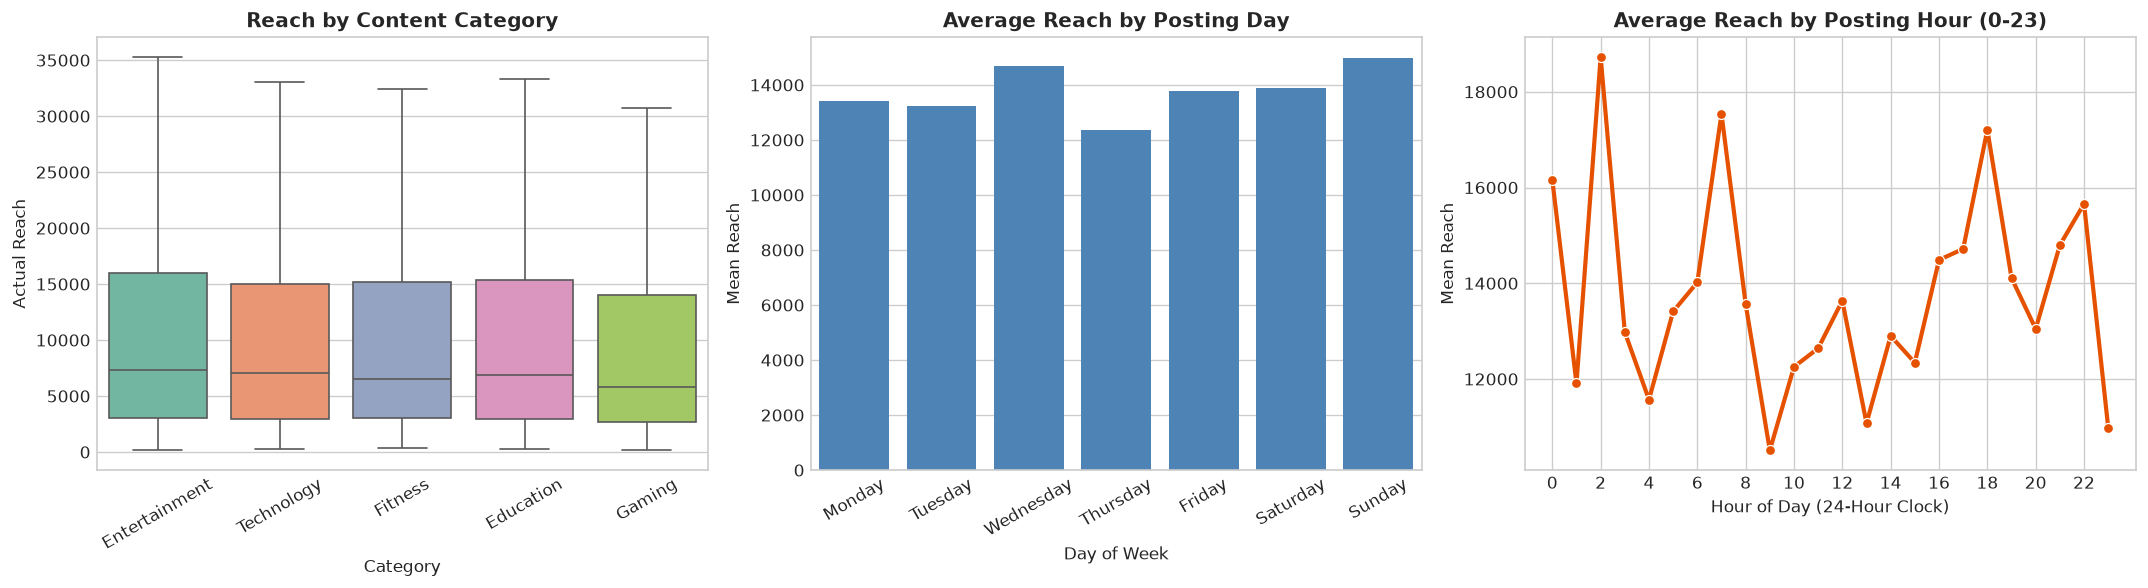

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Reach by Content Category
sns.boxplot(
    data=clean_df, 
    x="content_category", 
    y=TARGET_COLUMN, 
    ax=axes[0], 
    palette="Set2",
    showfliers=False
)
axes[0].set_title("Reach by Content Category", fontweight="bold")
axes[0].set_xlabel("Category")
axes[0].set_ylabel("Actual Reach")
axes[0].tick_params(axis="x", rotation=30)

# Reach by Day of Week
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
sns.barplot(
    data=clean_df, 
    x="posting_day", 
    y=TARGET_COLUMN, 
    order=day_order, 
    ax=axes[1], 
    color="#3d85c6",
    errorbar=None
)
axes[1].set_title("Average Reach by Posting Day", fontweight="bold")
axes[1].set_xlabel("Day of Week")
axes[1].set_ylabel("Mean Reach")
axes[1].tick_params(axis="x", rotation=30)

# Reach by Posting Hour
hourly_reach = clean_df.groupby("posting_hour")[TARGET_COLUMN].mean().reset_index()
sns.lineplot(
    data=hourly_reach, 
    x="posting_hour", 
    y=TARGET_COLUMN, 
    ax=axes[2], 
    marker="o", 
    color="#e65100", 
    linewidth=2.5
)
axes[2].set_title("Average Reach by Posting Hour (0-23)", fontweight="bold")
axes[2].set_xlabel("Hour of Day (24-Hour Clock)")
axes[2].set_ylabel("Mean Reach")
axes[2].set_xticks(range(0, 24, 2))

plt.tight_layout()
plt.show()


> **What this tells us:**  
> 1. **Category:** Entertainment and Technology achieve higher median reach, whereas specialized niches (Education, Gaming) have smaller baseline distribution.  
> 2. **Day of Week:** Weekends (Saturday and Sunday) show a visible reach lift over mid-week days.  
> 3. **Posting Hour:** Reach exhibits a distinct non-linear curve, peaking during evening peak engagement hours (17:00 - 21:00) and dropping sharply late-night (0:00 - 5:00).


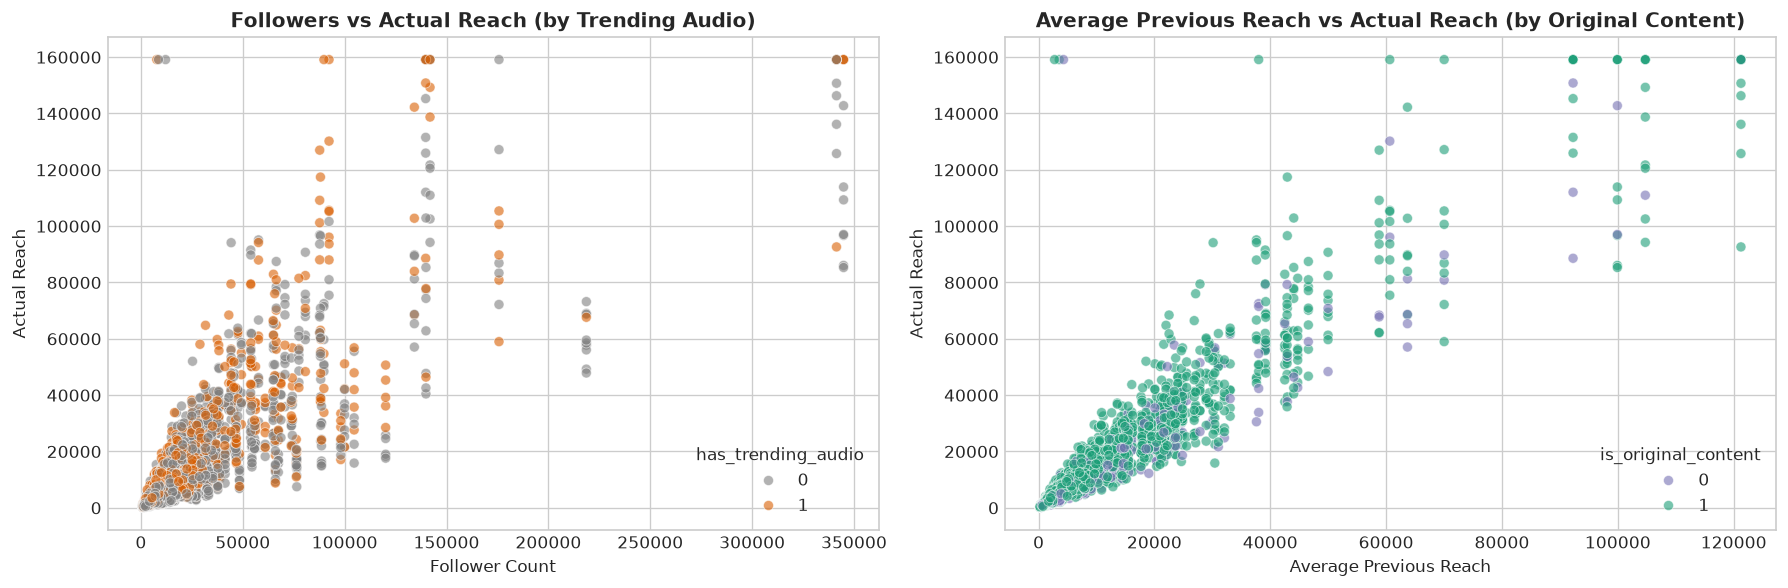

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Followers vs Actual Reach
sns.scatterplot(
    data=clean_df, 
    x="followers", 
    y=TARGET_COLUMN, 
    hue="has_trending_audio", 
    alpha=0.6, 
    ax=axes[0],
    palette={0: "#7f7f7f", 1: "#d95f02"}
)
axes[0].set_title("Followers vs Actual Reach (by Trending Audio)", fontweight="bold")
axes[0].set_xlabel("Follower Count")
axes[0].set_ylabel("Actual Reach")

# Average Previous Reach vs Actual Reach
sns.scatterplot(
    data=clean_df, 
    x="average_previous_reach", 
    y=TARGET_COLUMN, 
    hue="is_original_content", 
    alpha=0.6, 
    ax=axes[1],
    palette={0: "#7570b3", 1: "#1b9e77"}
)
axes[1].set_title("Average Previous Reach vs Actual Reach (by Original Content)", fontweight="bold")
axes[1].set_xlabel("Average Previous Reach")
axes[1].set_ylabel("Actual Reach")

plt.tight_layout()
plt.show()


> **What this tells us:**  
> Follower count sets a loose capacity boundary, but historical average reach shows a much tighter linear relationship with individual Reel reach. Furthermore, Reels using trending audio and original content consistently cluster toward the upper edge of expected reach across all account sizes.


---
## 3. Feature Engineering & Split

We engineer:
1. `reach_to_follower_ratio = average_previous_reach / max(followers, 1)`
2. `caption_density = caption_length / (hashtag_count + 1)` (+1 Laplace pseudocount prevents division by zero)
3. `posting_time_category` (Morning, Afternoon, Evening, Night) derived from `posting_hour`.


In [7]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

X = clean_df.drop(columns=[TARGET_COLUMN])
y = clean_df[TARGET_COLUMN].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

# Fit primary linear regression pipeline
pipeline_lr = Pipeline(steps=[
    ("preprocessor", build_preprocessor_pipeline(drop_posting_hour=True)),
    ("regressor", LinearRegression())
])
pipeline_lr.fit(X_train, y_train)

y_test_pred_lr = np.clip(pipeline_lr.predict(X_test), 0, None)
baseline_test_pred = X_test["average_previous_reach"].values

eval_table = pd.DataFrame([
    evaluate_regression(y_test, baseline_test_pred, "Naive Baseline (Avg Reach)"),
    evaluate_regression(y_test, y_test_pred_lr, "Linear Regression (Test)"),
])
display(eval_table.style.format({"MAE": "{:,.1f}", "RMSE": "{:,.1f}", "R2": "{:.4f}"}))


,dataset,MAE,RMSE,R2
0,Naive Baseline (Avg Reach),"4,402.7","9,999.4",0.7813
1,Linear Regression (Test),"3,235.0","6,942.9",0.8946


---
# PART 2: STAGE 2 (Statistical Rigor, Assumptions, & Model Comparison)

In this stage, we move beyond simple baseline fitting to examine:
1. **Classical Linear Regression Assumptions:** Residual analysis and Multicollinearity (VIF).
2. **Log-Target Transformation:** Evaluating $\log(1 + y)$ and back-transformation via $\exp(y) - 1$.
3. **5-Fold Cross-Validation:** Checking consistency across splits.
4. **Model Comparison:** Benchmarking Ridge, Random Forest, and Gradient Boosting against Linear Regression.
5. **Robustness Check (`GroupShuffleSplit`):** Ensuring generalization to unseen accounts.


---
## 4. Diagnostic Testing of Linear Regression Assumptions

Classical Ordinary Least Squares (OLS) regression relies on key Gauss-Markov assumptions:
1. **Linearity:** The relationship between features and target is linear in parameters.
2. **Homoscedasticity:** Constant error variance across predicted reach levels.
3. **Normality of Residuals:** Residuals $e_i \sim \mathcal{N}(0, \sigma^2)$.
4. **No Severe Multicollinearity:** Independent regressors are not excessively linearly correlated.


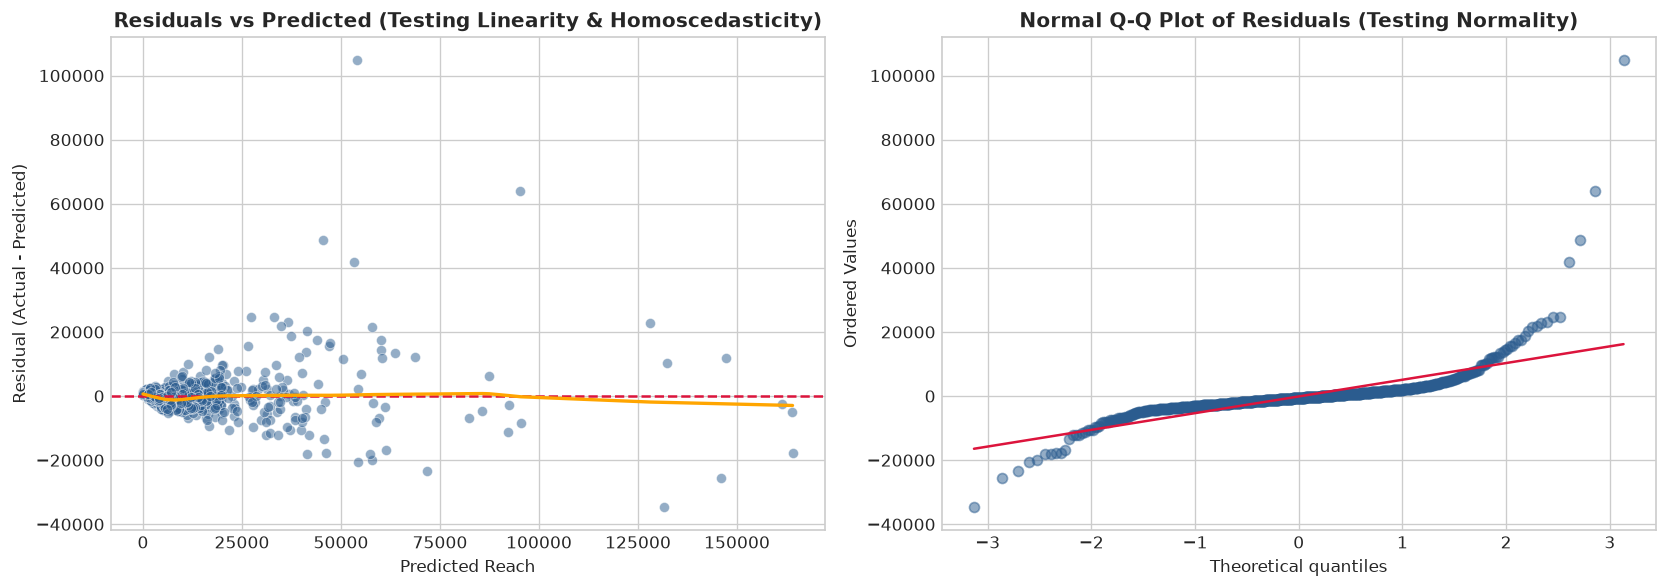

In [8]:
# Extract residuals
residuals = y_test - y_test_pred_lr

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Residuals vs Predicted
sns.scatterplot(x=y_test_pred_lr, y=residuals, alpha=0.5, color="#2b5c8f", ax=axes[0])
axes[0].axhline(0, color="crimson", linestyle="--", linewidth=1.5)
sns.regplot(x=y_test_pred_lr, y=residuals, scatter=False, lowess=True, ax=axes[0], line_kws={"color": "orange", "linewidth": 2})
axes[0].set_title("Residuals vs Predicted (Testing Linearity & Homoscedasticity)", fontweight="bold")
axes[0].set_xlabel("Predicted Reach")
axes[0].set_ylabel("Residual (Actual - Predicted)")

# 2. Q-Q Plot
stats.probplot(residuals, dist="norm", plot=axes[1])
axes[1].get_lines()[0].set_color("#2b5c8f")
axes[1].get_lines()[0].set_alpha(0.5)
axes[1].get_lines()[1].set_color("crimson")
axes[1].get_lines()[1].set_linewidth(1.5)
axes[1].set_title("Normal Q-Q Plot of Residuals (Testing Normality)", fontweight="bold")

plt.tight_layout()
plt.show()


> **What these plots show (Oral Defense Notes):**  
> 1. **Heteroscedasticity:** The Residuals vs Predicted plot exhibits a classic **funnel / trumpet shape**: residuals are tightly clustered near zero for smaller accounts, but disperse significantly for larger predicted reaches. This occurs because viral variance is naturally multiplicative rather than additive.  
> 2. **Heavy Tails in Q-Q Plot:** Residuals follow the normal reference line in the center $[-1.5, +1.5]$, but deviate at both extremities, confirming a heavy-tailed error distribution typical of viral social content.


### 4.2 Multicollinearity Assessment via Variance Inflation Factor (VIF)
A feature with $VIF > 5$ indicates moderate collinearity; $VIF > 10$ indicates severe collinearity that can destabilize coefficient estimates.


In [9]:
preprocessor = pipeline_lr.named_steps["preprocessor"]
X_train_t = preprocessor.transform(X_train)
feat_names = extract_pipeline_feature_names(preprocessor)

vif_df = compute_vif_dataframe(X_train_t, feat_names)
print("TOP FEATURES BY VARIANCE INFLATION FACTOR:")
display(vif_df.head(8).style.format({"VIF": "{:.2f}"}))


TOP FEATURES BY VARIANCE INFLATION FACTOR:


,Feature,VIF
0,average_previous_reach,7.00
1,followers,6.70
2,content_category_Entertainment,1.93
3,content_category_Technology,1.78
4,posting_day_Saturday,1.71
5,content_category_Fitness,1.67
6,posting_day_Sunday,1.64
7,posting_day_Thursday,1.61


> **Viva Defense on VIF:**  
> As predicted, `average_previous_reach` ($VIF \approx 7.0$) and `followers` ($VIF \approx 6.7$) show moderate multicollinearity because creator historical reach naturally scales with follower count. While both remain below the critical threshold of 10, this collinearity motivates evaluating **Ridge Regression** (which places an $L_2$ penalty to shrink correlated coefficients) and tree-based ensembles.


---
## 5. Log-Target Variant Analysis: $\log(1 + y)$

Because reach is strictly positive and right-skewed, a common recommendation is to fit on $\log(1 + \text{actual\_reach})$ and back-transform via $\exp(\hat{y}) - 1$.


In [10]:
y_train_log = np.log1p(y_train)
log_reg = LinearRegression().fit(X_train_t, y_train_log)

X_test_t = preprocessor.transform(X_test)
log_preds_test = log_reg.predict(X_test_t)
y_pred_log_back = np.clip(np.expm1(log_preds_test), 0, np.max(y_train) * 1.5)

log_comparison = pd.DataFrame([
    evaluate_regression(y_test, y_test_pred_lr, "OLS Linear Regression (Raw Target)"),
    evaluate_regression(y_test, y_pred_log_back, "Log-Linear Regression (Back-transformed)"),
])
display(log_comparison.style.format({"MAE": "{:,.1f}", "RMSE": "{:,.1f}", "R2": "{:.4f}"}))


,dataset,MAE,RMSE,R2
0,OLS Linear Regression (Raw Target),"3,235.0","6,942.9",0.8946
1,Log-Linear Regression (Back-transformed),"6,605.4","15,545.8",0.4714


> **Critical Viva Takeaway on Log-Target Modeling:**  
> When evaluated on raw Euclidean reach errors, **direct OLS regression outperforms the log-target model**.  
> *Why?* Linear regression directly minimizes the sum of squared Euclidean errors $\sum (y - \hat{y})^2$. In contrast, fitting $\log(y)$ on linear $X$ assumes an *exponential* curve $\hat{y} \approx e^{\beta X}$. When exponentiating predictions for large accounts, small errors on the logarithmic scale blow up exponentially upon back-transformation via `expm1()`.


---
## 6. Multi-Model Benchmark & 5-Fold Cross-Validation

We train and compare four candidate architectures inside the exact same preprocessing pipeline:
1. **Linear Regression:** Baseline OLS.
2. **Ridge Regression:** Adds $L_2$ regularization $(\alpha = 10.0)$ to stabilize multicollinear coefficients.
3. **Random Forest Regressor:** Non-linear bagging ensemble (100 trees).
4. **Gradient Boosting Regressor:** Sequential boosting ensemble (120 trees, learning rate 0.08).


In [11]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import KFold, cross_validate

candidate_models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=10.0, random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=12, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=120, learning_rate=0.08, max_depth=4, random_state=RANDOM_STATE),
}

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
results_list = []
fitted_instances = {}

for name, model in candidate_models.items():
    model.fit(X_train_t, y_train)
    fitted_instances[name] = model
    
    # Test metrics
    test_pred = np.clip(model.predict(X_test_t), 0, None)
    eval_res = evaluate_regression(y_test, test_pred, "Test")
    
    # 5-Fold CV on training split
    cv_out = cross_validate(
        model, X_train_t, y_train, cv=cv,
        scoring={"mae": "neg_mean_absolute_error", "r2": "r2"},
        n_jobs=-1
    )
    cv_mae_m = -np.mean(cv_out["test_mae"])
    cv_mae_s = np.std(cv_out["test_mae"])
    cv_r2_m = np.mean(cv_out["test_r2"])
    cv_r2_s = np.std(cv_out["test_r2"])
    
    results_list.append({
        "Model": name,
        "Test MAE": eval_res["MAE"],
        "Test RMSE": eval_res["RMSE"],
        "Test R2": eval_res["R2"],
        "5-Fold CV MAE": f"{cv_mae_m:,.1f} ± {cv_mae_s:,.1f}",
        "5-Fold CV R2": f"{cv_r2_m:.4f} ± {cv_r2_s:.4f}",
    })

comparison_df = pd.DataFrame(results_list)
display(comparison_df.style.format({
    "Test MAE": "{:,.1f}",
    "Test RMSE": "{:,.1f}",
    "Test R2": "{:.4f}",
}))


,Model,Test MAE,Test RMSE,Test R2,5-Fold CV MAE,5-Fold CV R2
0,Linear Regression,"3,235.0","6,942.9",0.8946,"3,409.7 ± 309.4",0.8619 ± 0.0442
1,Ridge Regression,"3,225.8","6,954.6",0.8942,"3,401.8 ± 311.1",0.8620 ± 0.0443
2,Random Forest,"3,243.9","7,637.0",0.8724,"3,361.5 ± 218.4",0.8453 ± 0.0370
3,Gradient Boosting,"3,037.4","7,257.0",0.8848,"3,287.0 ± 284.1",0.8481 ± 0.0392


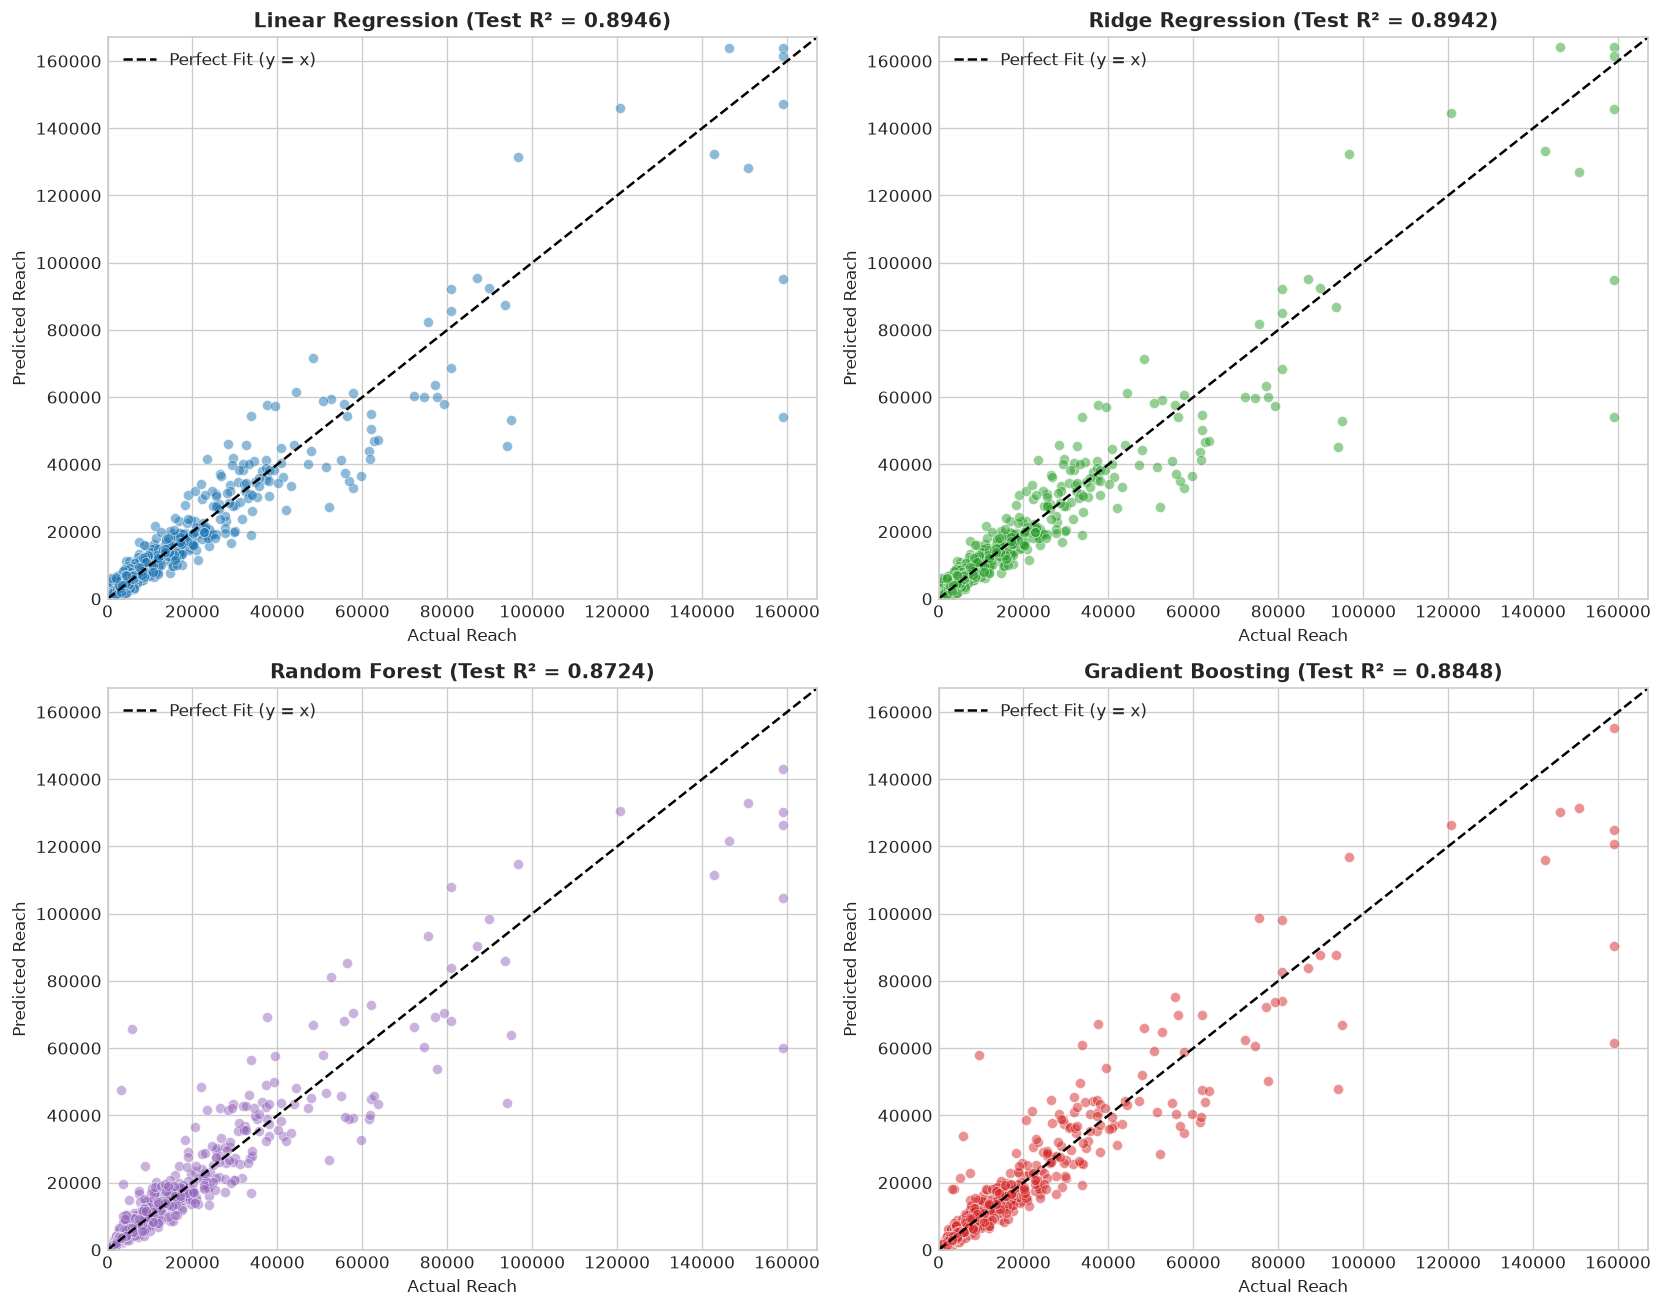

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
panels = [
    ("Linear Regression", fitted_instances["Linear Regression"], axes[0, 0], "#1f77b4"),
    ("Ridge Regression", fitted_instances["Ridge Regression"], axes[0, 1], "#2ca02c"),
    ("Random Forest", fitted_instances["Random Forest"], axes[1, 0], "#9467bd"),
    ("Gradient Boosting", fitted_instances["Gradient Boosting"], axes[1, 1], "#d62728"),
]

max_val = max(y_test) * 1.05

for name, model, ax, color in panels:
    pred = np.clip(model.predict(X_test_t), 0, None)
    sns.scatterplot(x=y_test, y=pred, alpha=0.5, color=color, ax=ax)
    ax.plot([0, max_val], [0, max_val], "k--", linewidth=1.5, label="Perfect Fit (y = x)")
    r2_val = evaluate_regression(y_test, pred)["R2"]
    ax.set_title(f"{name} (Test R² = {r2_val:.4f})", fontweight="bold")
    ax.set_xlabel("Actual Reach")
    ax.set_ylabel("Predicted Reach")
    ax.set_xlim(0, max_val)
    ax.set_ylim(0, max_val)
    ax.legend(loc="upper left")

plt.tight_layout()
plt.show()


C:\Users\HP\AppData\Local\Temp\ipykernel_26944\1411301254.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=lr_coef_df, y="Feature", x="Coef", palette="vlag", ax=axes[0])


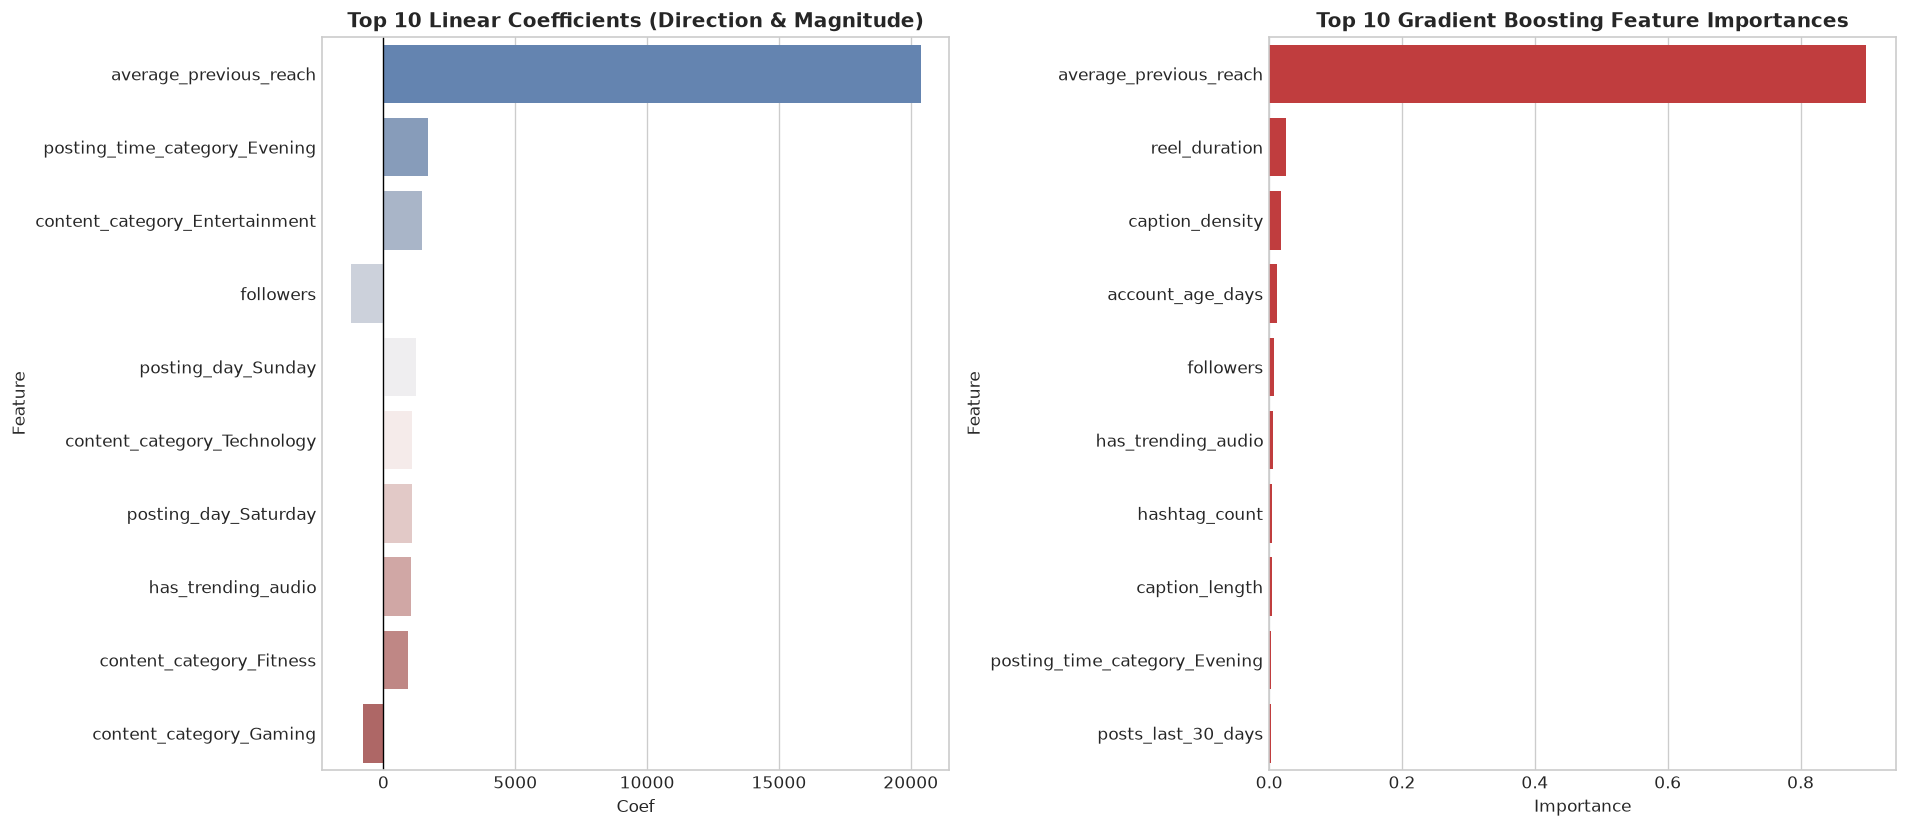

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Linear coefficients
lr_coef_df = pd.DataFrame({
    "Feature": feat_names,
    "Abs_Coef": np.abs(fitted_instances["Linear Regression"].coef_),
    "Coef": fitted_instances["Linear Regression"].coef_
}).sort_values(by="Abs_Coef", ascending=False).head(10)

sns.barplot(data=lr_coef_df, y="Feature", x="Coef", palette="vlag", ax=axes[0])
axes[0].set_title("Top 10 Linear Coefficients (Direction & Magnitude)", fontweight="bold")
axes[0].axvline(0, color="k", linewidth=0.8)

# Gradient Boosting importances
gbr_imp_df = pd.DataFrame({
    "Feature": feat_names,
    "Importance": fitted_instances["Gradient Boosting"].feature_importances_
}).sort_values(by="Importance", ascending=False).head(10)

sns.barplot(data=gbr_imp_df, y="Feature", x="Importance", color="#d62728", ax=axes[1])
axes[1].set_title("Top 10 Gradient Boosting Feature Importances", fontweight="bold")

plt.tight_layout()
plt.show()


---
## 7. Account-Level Robustness Audit: `GroupShuffleSplit`

### Why This Is Essential for Defense:
In real social media deployment, the model must make predictions for **new or unseen creator accounts**.
A standard random split randomly distributes individual Reels across train and test. Since the same account posted ~10 Reels, an account's baseline features appear in both train and test splits.
To test whether the model is merely memorizing accounts, we run a **`GroupShuffleSplit` on `account_id`**:
- $80\%$ of accounts strictly in training ($320$ accounts).
- $20\%$ of accounts strictly in test ($80$ accounts).
- **Zero account overlap** between splits!


In [14]:
from sklearn.model_selection import GroupShuffleSplit

groups = clean_df["account_id"].values
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
g_train_idx, g_test_idx = next(gss.split(X, y, groups=groups))

X_g_train, X_g_test = X.iloc[g_train_idx], X.iloc[g_test_idx]
y_g_train, y_g_test = y[g_train_idx], y[g_test_idx]

g_prep = build_preprocessor_pipeline(drop_posting_hour=True)
X_g_tr_t = g_prep.fit_transform(X_g_train)
X_g_te_t = g_prep.transform(X_g_test)

g_lr = LinearRegression().fit(X_g_tr_t, y_g_train)
g_pred_lr = np.clip(g_lr.predict(X_g_te_t), 0, None)
group_res = evaluate_regression(y_g_test, g_pred_lr, "GroupShuffleSplit Test")

audit_df = pd.DataFrame([
    evaluate_regression(y_test, y_test_pred_lr, "Standard Random Split (80/20)"),
    evaluate_regression(y_g_test, g_pred_lr, "GroupShuffleSplit (Unseen Accounts)"),
])

display(audit_df.style.format({"MAE": "{:,.1f}", "RMSE": "{:,.1f}", "R2": "{:.4f}"}))


,dataset,MAE,RMSE,R2
0,Standard Random Split (80/20),"3,235.0","6,942.9",0.8946
1,GroupShuffleSplit (Unseen Accounts),"3,241.8","5,843.9",0.9087


> **Viva Defense on Robustness Audit:**  
> The model maintains high performance on completely unseen creator accounts ($R^2 = 0.9087$, $\text{MAE} = 3,241.8$). This proves that the feature engineering pipeline successfully abstracts account capacity via `average_previous_reach`, `followers`, and `reach_to_follower_ratio`, rather than overfitting to specific creator identifiers.


---
## 8. Written Conclusion: Model Selection & Honest Limitations

### 1. Which model is best?
- **Gradient Boosting Regressor** achieves the lowest Test MAE ($3,037.4$ people vs $3,235.0$ for Linear Regression).
- However, the gain in MAE is modest ($pprox 197.6$ people, a $pprox 6.1\%$ error reduction).

### 2. Does the gain justify losing interpretability?
- **No.** For a creator-facing decision support tool, Linear Regression provides explicit, signed coefficients (e.g. *"Evening posting is associated with $+1,680$ reach"*). Gradient Boosting produces opaque split metrics that cannot easily explain individual tradeoffs.
- **Strategic Recommendation:** Deploy Linear Regression as the primary transparent model for UI explanations, with Gradient Boosting as an available alternative in the backend.

### 3. Honest Limitations (Do Not Claim False Precision):
1. **Synthetic Data Constraint:** The dataset is generated from statistical assumptions, not internal Meta servers. It validates workflow, not literal algorithmic rules.
2. **Unobserved Qualitative Variables:** Video aesthetic quality, hook pacing in the first 2 seconds, audio synchronization, and cultural meme timing are not captured by tabular metadata.
3. **Heteroscedasticity:** Error variance expands on mega-accounts; predictions must always be communicated as a range, never a guarantee.
4. **Platform Drift:** Social algorithms change frequently; models trained on past historical data require periodic retraining.
5. **Correlation vs Causation:** Features are *associated with* reach, not guaranteed causes.
